<a href="https://colab.research.google.com/github/Manju-123469/Olive-Tree-Detection-and-Counting/blob/main/Deep_Learning_Model_for_Detecting_and_Counting_Olive_Trees_in_Satellite_Imagery.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch

print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("GPU:", torch.cuda.get_device_name(0))
else:
    device = torch.device("cpu")
    print("Using CPU")

PyTorch Version: 2.14.1+cu130
CUDA Available: True
GPU: Tesla T4


In [ ]:
!pip install timm opencv-python scipy pycocotools matplotlib tqdm

In [ ]:
import os
import json
import cv2
import timm
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from scipy.ndimage import gaussian_filter
from tqdm import tqdm

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
base_path = "/content/drive/MyDrive/Olive_CNN_Project/Olive_Project/OliveSatelital_v1.0"

print("Dataset exists:", os.path.exists(base_path))

for split in ["train", "val", "test"]:

    split_path = os.path.join(base_path, "dataset", split)

    image_path = os.path.join(split_path, "images")
    annotation_path = os.path.join(split_path, "labels.json")

    print("\n", split.upper())
    print("Image folder exists:", os.path.exists(image_path))
    print("Annotation file exists:", os.path.exists(annotation_path))

    if os.path.exists(image_path):
        print("Number of images:", len(os.listdir(image_path)))

Dataset exists: True

 TRAIN
Image folder exists: True
Annotation file exists: True
Number of images: 1124

 VAL
Image folder exists: True
Annotation file exists: True
Number of images: 141

 TEST
Image folder exists: True
Annotation file exists: True
Number of images: 140


In [ ]:
train_json = os.path.join(
    base_path,
    "dataset",
    "train",
    "labels.json"
)

with open(train_json, "r") as f:
    train_data = json.load(f)

print("Total training images:", len(train_data["images"]))
print("Total annotations:", len(train_data["annotations"]))

print("\nFirst image information:")
print(train_data["images"][0])

print("\nFirst annotation:")
print(train_data["annotations"][0])

Total training images: 1124
Total annotations: 12246

First image information:
{'id': 1, 'file_name': '6ab36d8f177250154456a82f.jpg', 'height': 640, 'width': 960, 'license': None, 'coco_url': None}

First annotation:
{'id': 1, 'image_id': 1, 'category_id': 1, 'bbox': [633.0, 261.0, 136.0, 135.0], 'area': 18360.0, 'iscrowd': 0, 'blur_variance': 5240.484263293949, 'derived_label': 'olivo', 'source_field': 'yolo_detections', 'source_label': 'olivo'}


In [ ]:
def generate_density_map(height, width, annotations, sigma=4):

    density = np.zeros((height, width), dtype=np.float32)

    for ann in annotations:

        x, y, w, h = ann["bbox"]

        center_x = int(x + w / 2)
        center_y = int(y + h / 2)

        if 0 <= center_x < width and 0 <= center_y < height:
            density[center_y, center_x] += 1

    density = gaussian_filter(density, sigma=sigma)

    # Preserve total tree count
    if density.sum() > 0:
        density *= len(annotations) / density.sum()

    return density

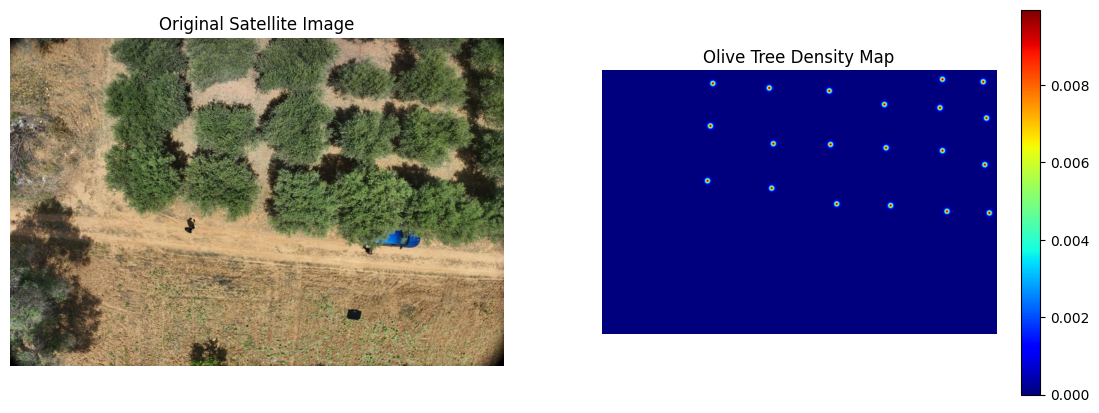

Image shape: (640, 960, 3)
Density map shape: (640, 960)
Actual tree count: 20
Density map count: 20.0


In [ ]:
# Group annotations by image ID

annotations_by_image = {}

for ann in train_data["annotations"]:

    image_id = ann["image_id"]

    if image_id not in annotations_by_image:
        annotations_by_image[image_id] = []

    annotations_by_image[image_id].append(ann)


# Load first training image

sample = train_data["images"][0]

image_path = os.path.join(
    base_path,
    "dataset",
    "train",
    "images",
    sample["file_name"]
)

image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

height, width = image.shape[:2]

annotations = annotations_by_image.get(sample["id"], [])

density_map = generate_density_map(
    height,
    width,
    annotations
)


# Display results

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Satellite Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(density_map, cmap="jet")
plt.title("Olive Tree Density Map")
plt.colorbar()
plt.axis("off")

plt.show()

print("Image shape:", image.shape)
print("Density map shape:", density_map.shape)
print("Actual tree count:", len(annotations))
print("Density map count:", density_map.sum())

In [ ]:
class OliveTreeDataset(Dataset):

    def __init__(self, base_path, split, input_size=224):

        self.base_path = base_path
        self.split = split
        self.input_size = input_size

        self.image_dir = os.path.join(
            base_path, "dataset", split, "images"
        )

        json_path = os.path.join(
            base_path, "dataset", split, "labels.json"
        )

        with open(json_path, "r") as f:
            self.data = json.load(f)

        self.images = self.data["images"]

        self.annotations_by_image = {}

        for ann in self.data["annotations"]:

            image_id = ann["image_id"]

            if image_id not in self.annotations_by_image:
                self.annotations_by_image[image_id] = []

            self.annotations_by_image[image_id].append(ann)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):

        image_info = self.images[index]

        image_path = os.path.join(
            self.image_dir,
            image_info["file_name"]
        )

        image = cv2.imread(image_path)

        if image is None:
            raise RuntimeError(f"Cannot read image: {image_path}")

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        height, width = image.shape[:2]

        annotations = self.annotations_by_image.get(
            image_info["id"], []
        )

        # Generate density map
        density = generate_density_map(
            height,
            width,
            annotations
        )

        # Resize image
        image = cv2.resize(
            image,
            (self.input_size, self.input_size)
        )

        # Resize density map
        density = cv2.resize(
            density,
            (self.input_size, self.input_size),
            interpolation=cv2.INTER_LINEAR
        )

        # Preserve tree count
        original_count = len(annotations)

        if density.sum() > 0:
            density *= original_count / density.sum()

        # Normalize image
        image = image.astype(np.float32) / 255.0

        mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
        std = np.array([0.229, 0.224, 0.225], dtype=np.float32)

        image = (image - mean) / std

        # Convert to PyTorch tensors
        image = torch.from_numpy(
            image.transpose(2, 0, 1).copy()
        ).float()

        density = torch.from_numpy(
            density.copy()
        ).unsqueeze(0).float()

        return image, density

In [ ]:
from torch.utils.data import DataLoader

train_dataset = OliveTreeDataset(
    base_path, "train"
)

val_dataset = OliveTreeDataset(
    base_path, "val"
)

test_dataset = OliveTreeDataset(
    base_path, "test"
)

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

Training images: 1124
Validation images: 141
Testing images: 140


In [ ]:
images, densities = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Density batch shape:", densities.shape)

print("Actual tree counts:")
print(densities.sum(dim=(1, 2, 3)))

print("GPU:", device)

Image batch shape: torch.Size([4, 3, 224, 224])
Density batch shape: torch.Size([4, 1, 224, 224])
Actual tree counts:
tensor([12.0000,  2.0000,  2.0000,  6.0000])


NameError: name 'device' is not defined

In [ ]:
import timm
import torch

encoder = timm.create_model(
    "swin_tiny_patch4_window7_224",
    pretrained=True,
    features_only=True,
    out_indices=(0, 1, 2, 3)
)

encoder = encoder.to(device)

print("Swin Transformer loaded successfully!")

print("Feature channels:", encoder.feature_info.channels())
print("Feature reductions:", encoder.feature_info.reduction())

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

NameError: name 'device' is not defined

In [ ]:
dummy_input = torch.randn(
    1, 3, 224, 224
).to(device)

encoder.eval()

with torch.no_grad():
    features = encoder(dummy_input)

print("Number of feature stages:", len(features))

for i, feature in enumerate(features):
    print(
        f"Stage {i+1}:",
        feature.shape
    )

Number of feature stages: 4
Stage 1: torch.Size([1, 56, 56, 96])
Stage 2: torch.Size([1, 28, 28, 192])
Stage 3: torch.Size([1, 14, 14, 384])
Stage 4: torch.Size([1, 7, 7, 768])


In [ ]:

class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels):

        super().__init__()

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class OliveSwinUNet(nn.Module):

    def __init__(self):

        super().__init__()

        # Swin Transformer Encoder
        self.encoder = timm.create_model(
            "swin_tiny_patch4_window7_224",
            pretrained=True,
            features_only=True,
            out_indices=(0, 1, 2, 3)
        )

        # U-Net Decoder
        self.decoder3 = ConvBlock(768 + 384, 384)

        self.decoder2 = ConvBlock(384 + 192, 192)

        self.decoder1 = ConvBlock(192 + 96, 96)

        # Final density map prediction layer
        self.final_conv = nn.Conv2d(
            96,
            1,
            kernel_size=1
        )

    def forward(self, x):

        # Encoder feature extraction
        f1, f2, f3, f4 = self.encoder(x)

        # Convert NHWC format to NCHW format
        f1 = f1.permute(0, 3, 1, 2).contiguous()
        f2 = f2.permute(0, 3, 1, 2).contiguous()
        f3 = f3.permute(0, 3, 1, 2).contiguous()
        f4 = f4.permute(0, 3, 1, 2).contiguous()

        # Decoder Stage 3
        x = F.interpolate(
            f4,
            size=f3.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        x = torch.cat([x, f3], dim=1)

        x = self.decoder3(x)

        # Decoder Stage 2
        x = F.interpolate(
            x,
            size=f2.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        x = torch.cat([x, f2], dim=1)

        x = self.decoder2(x)

        # Decoder Stage 1
        x = F.interpolate(
            x,
            size=f1.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        x = torch.cat([x, f1], dim=1)

        x = self.decoder1(x)

        # Upsample to original input resolution
        x = F.interpolate(
            x,
            size=(224, 224),
            mode="bilinear",
            align_corners=False
        )

        # Predict density map
        x = self.final_conv(x)

        return x


print("Swin Transformer U-Net architecture defined successfully!")


Swin Transformer U-Net architecture defined successfully!


In [ ]:
model = OliveSwinUNet().to(device)

print("Model created successfully!")

total_params = sum(
    p.numel() for p in model.parameters()
)

print("Total parameters:", total_params)

Model created successfully!
Total parameters: 34489243


In [ ]:
model.eval()

with torch.no_grad():

    sample_input = torch.randn(
        2, 3, 224, 224
    ).to(device)

    output = model(sample_input)

print("Input shape:", sample_input.shape)
print("Output shape:", output.shape)

print("Output minimum:", output.min().item())
print("Output maximum:", output.max().item())

print("Contains NaN:", torch.isnan(output).any().item())

Input shape: torch.Size([2, 3, 224, 224])
Output shape: torch.Size([2, 1, 224, 224])
Output minimum: -0.15294310450553894
Output maximum: 0.04407794028520584
Contains NaN: False


In [ ]:
import torch.optim as optim

# Loss function
criterion = nn.MSELoss()

# Optimizer
optimizer = optim.SGD(
    model.parameters(),
    lr=0.001,
    momentum=0.9,
    weight_decay=0.0001
)

print("Loss function: MSE")
print("Optimizer: SGD")
print("Learning rate: 0.001")
print("Momentum: 0.9")
print("Weight decay: 0.0001")

Loss function: MSE
Optimizer: SGD
Learning rate: 0.001
Momentum: 0.9
Weight decay: 0.0001


In [ ]:

# CELL 18: MODEL TRAINING

num_epochs = 10

best_val_mae = float("inf")

# Store training history for plotting in Cell 19
train_losses = []
val_losses = []
val_maes = []

# Create folder to save trained models
save_dir = os.path.join(base_path, "trained_models")
os.makedirs(save_dir, exist_ok=True)

for epoch in range(num_epochs):

    # ---------------- TRAINING ----------------
    model.train()
    train_loss = 0.0

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch [{epoch+1}/{num_epochs}] Training"
    )

    for images, densities in train_bar:

        images = images.to(device)
        densities = densities.to(device)

        optimizer.zero_grad()

        predictions = model(images)

        loss = criterion(predictions, densities)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        train_loss += loss.item()

        train_bar.set_postfix(loss=loss.item())

    train_loss /= len(train_loader)

    # ---------------- VALIDATION ----------------
    model.eval()

    val_loss = 0.0
    val_mae = 0.0

    with torch.no_grad():

        for images, densities in val_loader:

            images = images.to(device)
            densities = densities.to(device)

            predictions = model(images)

            loss = criterion(predictions, densities)

            val_loss += loss.item()

            # Calculate predicted and actual tree counts
            predicted_counts = predictions.clamp(min=0).sum(
                dim=(1, 2, 3)
            )

            actual_counts = densities.sum(
                dim=(1, 2, 3)
            )

            batch_mae = torch.abs(
                predicted_counts - actual_counts
            ).sum()

            val_mae += batch_mae.item()

    val_loss /= len(val_loader)
    val_mae /= len(val_dataset)

    # Store values for graphs
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_maes.append(val_mae)

    # Display epoch results
    print(f"\nEpoch [{epoch+1}/{num_epochs}]")
    print(f"Train Loss: {train_loss:.6f}")
    print(f"Validation Loss: {val_loss:.6f}")
    print(f"Count MAE: {val_mae:.2f}")

    # Save best model
    if val_mae < best_val_mae:

        best_val_mae = val_mae

        torch.save(
            model.state_dict(),
            os.path.join(save_dir, "best_olive_swin_unet.pth")
        )

        print("Best model saved successfully!")

    # Save latest model
    torch.save(
        model.state_dict(),
        os.path.join(save_dir, "latest_olive_swin_unet.pth")
    )

print("\nTraining completed!")
print("Best Validation MAE:", best_val_mae)
print("Models saved in:", save_dir)


Epoch [1/10] Training: 100%|██████████| 281/281 [02:15<00:00,  2.07it/s, loss=0.00254]



Epoch [1/10]
Train Loss: 0.003805
Validation Loss: 0.002141
Count MAE: 871.27
Best model saved successfully!


Epoch [2/10] Training: 100%|██████████| 281/281 [00:47<00:00,  5.86it/s, loss=0.00112]



Epoch [2/10]
Train Loss: 0.001645
Validation Loss: 0.001236
Count MAE: 672.23
Best model saved successfully!


Epoch [3/10] Training: 100%|██████████| 281/281 [00:53<00:00,  5.21it/s, loss=0.000813]



Epoch [3/10]
Train Loss: 0.001040
Validation Loss: 0.000848
Count MAE: 556.42
Best model saved successfully!


... (10 outputs left out)

Epoch [9/10] Training: 100%|██████████| 281/281 [00:55<00:00,  5.07it/s, loss=0.00034]



Epoch [9/10]
Train Loss: 0.000326
Validation Loss: 0.000302
Count MAE: 333.29
Best model saved successfully!


Epoch [10/10] Training: 100%|██████████| 281/281 [00:55<00:00,  5.06it/s, loss=0.000363]



Epoch [10/10]
Train Loss: 0.000287
Validation Loss: 0.000267
Count MAE: 309.37
Best model saved successfully!

Training completed!
Best Validation MAE: 309.365339563248
Models saved in: /content/drive/MyDrive/Olive_CNN_Project/Olive_Project/OliveSatelital_v1.0/trained_models


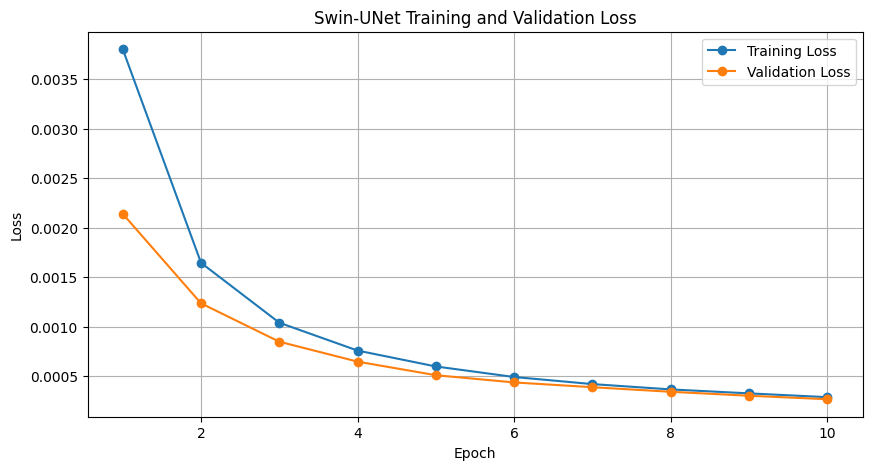

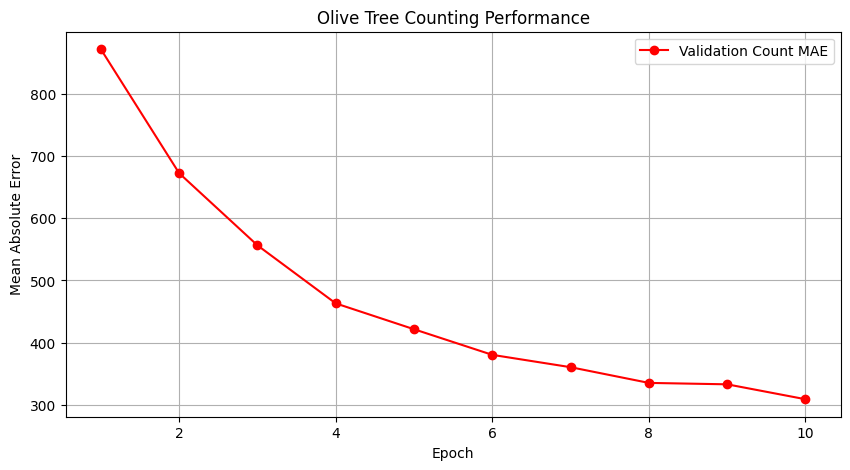

In [ ]:

# CELL 19: TRAINING AND VALIDATION GRAPHS

import matplotlib.pyplot as plt

# Plot training and validation loss
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(train_losses) + 1),
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    range(1, len(val_losses) + 1),
    val_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Swin-UNet Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.show()


# Plot validation counting error
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(val_maes) + 1),
    val_maes,
    marker="o",
    color="red",
    label="Validation Count MAE"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Absolute Error")
plt.title("Olive Tree Counting Performance")

plt.legend()
plt.grid(True)
plt.show()


In [ ]:

# CELL 20: LOAD BEST TRAINED MODEL

best_model_path = os.path.join(
    save_dir,
    "best_olive_swin_unet.pth"
)

model.load_state_dict(
    torch.load(best_model_path, map_location=device)
)

model.to(device)
model.eval()

print("Best Swin-UNet model loaded successfully!")
print("Best Validation MAE:", best_val_mae)

Best Swin-UNet model loaded successfully!
Best Validation MAE: 309.365339563248


In [ ]:

# CELL 21: TEST MODEL EVALUATION

model.eval()

test_loss = 0.0
test_mae = 0.0

with torch.no_grad():

    for images, densities in tqdm(test_loader, desc="Testing"):

        images = images.to(device)
        densities = densities.to(device)

        predictions = model(images)

        loss = criterion(predictions, densities)
        test_loss += loss.item()

        predicted_counts = predictions.clamp(min=0).sum(
            dim=(1, 2, 3)
        )

        actual_counts = densities.sum(
            dim=(1, 2, 3)
        )

        test_mae += torch.abs(
            predicted_counts - actual_counts
        ).sum().item()

test_loss /= len(test_loader)
test_mae /= len(test_dataset)

print("\nTEST RESULTS")
print("-------------------------")
print(f"Test Loss: {test_loss:.6f}")
print(f"Test Count MAE: {test_mae:.2f}")


Testing: 100%|██████████| 35/35 [00:31<00:00,  1.12it/s]


TEST RESULTS
-------------------------
Test Loss: 0.000267
Test Count MAE: 311.17


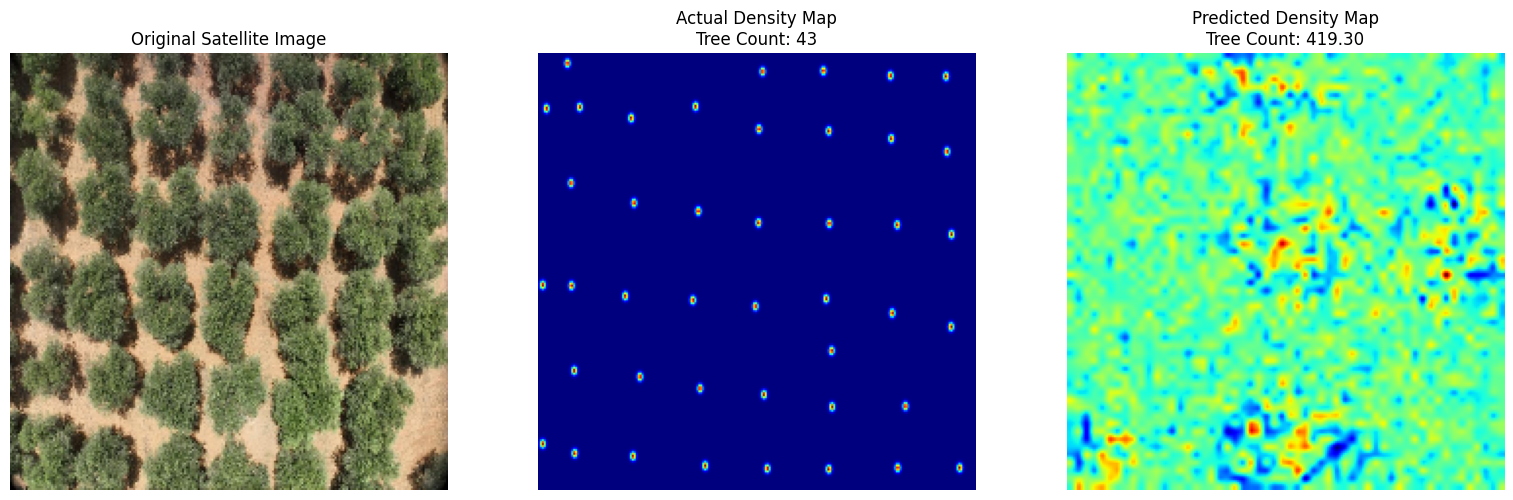

Actual Tree Count: 43
Predicted Tree Count: 419.3
Absolute Counting Error: 376.3


In [ ]:

# CELL 22: VISUALIZE OLIVE TREE PREDICTION

import matplotlib.pyplot as plt
import numpy as np
import torch

model.eval()

# Get one batch from test dataset
images, densities = next(iter(test_loader))

images = images.to(device)
densities = densities.to(device)

with torch.no_grad():
    predictions = model(images)

# Select first image
image = images[0].cpu().numpy()
actual_density = densities[0, 0].cpu().numpy()
predicted_density = predictions[0, 0].cpu().numpy()

# Calculate counts
actual_count = actual_density.sum()
predicted_count = np.maximum(predicted_density, 0).sum()

# Reverse ImageNet normalization
mean = np.array([0.485, 0.456, 0.406]).reshape(3, 1, 1)
std = np.array([0.229, 0.224, 0.225]).reshape(3, 1, 1)

image = image * std + mean
image = np.clip(image, 0, 1)
image = np.transpose(image, (1, 2, 0))

# Display results
plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original Satellite Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(actual_density, cmap="jet")
plt.title(f"Actual Density Map\nTree Count: {actual_count:.0f}")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(predicted_density, cmap="jet")
plt.title(f"Predicted Density Map\nTree Count: {predicted_count:.2f}")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Actual Tree Count:", round(float(actual_count)))
print("Predicted Tree Count:", round(float(predicted_count), 2))
print("Absolute Counting Error:", round(abs(float(actual_count) - float(predicted_count)), 2))


In [ ]:

# CELL 23: DENSITY MAP DIAGNOSTICS

# Inspect one batch from the test dataset
images, densities = next(iter(test_loader))

images = images.to(device)
densities = densities.to(device)

with torch.no_grad():
    predictions = model(images)

print("DENSITY MAP DIAGNOSTICS")
print("------------------------------")

for i in range(min(4, len(images))):

    actual_count = densities[i].sum().item()

    raw_prediction_sum = predictions[i].sum().item()

    predicted_count = predictions[i].clamp(min=0).sum().item()

    print(f"\nImage {i+1}")
    print("Actual density sum:", round(actual_count, 2))
    print("Raw prediction sum:", round(raw_prediction_sum, 2))
    print("Clamped prediction sum:", round(predicted_count, 2))

print("\nDensity map minimum:", densities.min().item())
print("Density map maximum:", densities.max().item())

print("\nPrediction minimum:", predictions.min().item())
print("Prediction maximum:", predictions.max().item())


DENSITY MAP DIAGNOSTICS
------------------------------

Image 1
Actual density sum: 43.0
Raw prediction sum: 93.17
Clamped prediction sum: 419.3

Image 2
Actual density sum: 44.0
Raw prediction sum: 108.63
Clamped prediction sum: 418.65

Image 3
Actual density sum: 28.0
Raw prediction sum: 80.42
Clamped prediction sum: 365.87

Image 4
Actual density sum: 37.0
Raw prediction sum: 82.75
Clamped prediction sum: 367.04

Density map minimum: 0.0
Density map maximum: 0.12070214003324509

Prediction minimum: -0.11176417768001556
Prediction maximum: 0.12793268263339996


In [ ]:

# CELL 24: COMPARE RAW AND CLAMPED COUNTING ERRORS

model.eval()

raw_mae = 0.0
clamped_mae = 0.0

with torch.no_grad():

    for images, densities in tqdm(test_loader, desc="Count comparison"):

        images = images.to(device)
        densities = densities.to(device)

        predictions = model(images)

        actual_counts = densities.sum(dim=(1, 2, 3))

        # Count without clamping negative values
        raw_counts = predictions.sum(dim=(1, 2, 3))

        # Count after clamping negative values
        clamped_counts = predictions.clamp(min=0).sum(dim=(1, 2, 3))

        raw_mae += torch.abs(
            raw_counts - actual_counts
        ).sum().item()

        clamped_mae += torch.abs(
            clamped_counts - actual_counts
        ).sum().item()

raw_mae /= len(test_dataset)
clamped_mae /= len(test_dataset)

print("\nCOUNTING ERROR COMPARISON")
print("------------------------------")
print(f"Raw Prediction MAE: {raw_mae:.2f}")
print(f"Clamped Prediction MAE: {clamped_mae:.2f}")


Count comparison: 100%|██████████| 35/35 [00:05<00:00,  5.88it/s]


COUNTING ERROR COMPARISON
------------------------------
Raw Prediction MAE: 46.89
Clamped Prediction MAE: 311.17


In [ ]:

# CELL 25: VERIFY DENSITY MAP RESIZING

import numpy as np
import cv2

# Select one training image
sample_image_id = train_dataset.image_ids[0]

sample_annotations = train_dataset.annotations[
    sample_image_id
]

# Read original image
sample_info = train_dataset.images[
    sample_image_id
]

image_path = os.path.join(
    train_dataset.image_dir,
    sample_info["file_name"]
)

original_image = cv2.imread(image_path)

original_height, original_width = original_image.shape[:2]

# Generate original density map
original_density = generate_density_map(
    original_height,
    original_width,
    sample_annotations
)

# Resize density map
resized_density = cv2.resize(
    original_density,
    (224, 224),
    interpolation=cv2.INTER_LINEAR
)

print("Original image shape:", original_image.shape)
print("Original density sum:", original_density.sum())

print("Resized density shape:", resized_density.shape)
print("Resized density sum:", resized_density.sum())

print("Actual annotation count:", len(sample_annotations))


AttributeError: 'OliveTreeDataset' object has no attribute 'image_ids'

In [ ]:

# CHECK DATASET ATTRIBUTES

print("Dataset attributes:")
print(train_dataset.__dict__.keys())


Dataset attributes:
dict_keys(['base_path', 'split', 'input_size', 'image_dir', 'data', 'images', 'annotations_by_image'])


In [ ]:

# CELL 25: VERIFY DENSITY MAP RESIZING

import numpy as np
import cv2

# Select the first training image
sample_image_id = train_dataset.data["images"][0]["id"]

# Get image information
sample_info = train_dataset.images[sample_image_id]

# Get annotations for this image
sample_annotations = train_dataset.annotations_by_image.get(
    sample_image_id, []
)

# Read original image
image_path = os.path.join(
    train_dataset.image_dir,
    sample_info["file_name"]
)

original_image = cv2.imread(image_path)

original_height, original_width = original_image.shape[:2]

# Generate original density map
original_density = generate_density_map(
    original_height,
    original_width,
    sample_annotations
)

# Resize density map
resized_density = cv2.resize(
    original_density,
    (224, 224),
    interpolation=cv2.INTER_LINEAR
)

print("Original image shape:", original_image.shape)
print("Original density sum:", original_density.sum())

print("Resized density shape:", resized_density.shape)
print("Resized density sum:", resized_density.sum())

print("Actual annotation count:", len(sample_annotations))


Original image shape: (640, 960, 3)
Original density sum: 20.0
Resized density shape: (224, 224)
Resized density sum: 1.6314747
Actual annotation count: 20


In [ ]:

# CELL 26: CHECK DATASET DENSITY COUNT

sample_image, sample_density = train_dataset[0]

sample_image_id = train_dataset.data["images"][0]["id"]

actual_annotations = train_dataset.annotations_by_image.get(
    sample_image_id, []
)

print("Image tensor shape:", sample_image.shape)
print("Density tensor shape:", sample_density.shape)

print("Actual annotation count:", len(actual_annotations))
print("Dataset density sum:", sample_density.sum().item())


Image tensor shape: torch.Size([3, 224, 224])
Density tensor shape: torch.Size([1, 224, 224])
Actual annotation count: 20
Dataset density sum: 20.0


In [ ]:

# CELL 27: COUNT-AWARE FINE-TUNING

import torch.optim as optim
import torch.nn.functional as F

# Start from the existing best model
model.load_state_dict(
    torch.load(best_model_path, map_location=device)
)

model.to(device)

# Use a smaller learning rate for fine-tuning
fine_optimizer = optim.AdamW(
    model.parameters(),
    lr=0.00001,
    weight_decay=0.0001
)

fine_epochs = 5

best_count_mae = float("inf")

fine_model_path = os.path.join(
    save_dir,
    "best_olive_swin_unet_countaware.pth"
)

for epoch in range(fine_epochs):

    model.train()

    total_loss = 0.0

    for images, densities in tqdm(
        train_loader,
        desc=f"Fine-tuning Epoch [{epoch+1}/{fine_epochs}]"
    ):

        images = images.to(device)
        densities = densities.to(device)

        fine_optimizer.zero_grad()

        predictions = model(images)

        # Density-map loss
        density_loss = F.mse_loss(
            predictions,
            densities
        )

        # Counting loss using raw density sums
        predicted_counts = predictions.sum(
            dim=(1, 2, 3)
        )

        actual_counts = densities.sum(
            dim=(1, 2, 3)
        )

        count_loss = F.l1_loss(
            predicted_counts,
            actual_counts
        ) / (224 * 224)

        # Combined loss
        loss = density_loss + count_loss

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        fine_optimizer.step()

        total_loss += loss.item()

    train_loss = total_loss / len(train_loader)

    # Validation
    model.eval()

    val_mae = 0.0

    with torch.no_grad():

        for images, densities in val_loader:

            images = images.to(device)
            densities = densities.to(device)

            predictions = model(images)

            predicted_counts = predictions.sum(
                dim=(1, 2, 3)
            )

            actual_counts = densities.sum(
                dim=(1, 2, 3)
            )

            val_mae += torch.abs(
                predicted_counts - actual_counts
            ).sum().item()

    val_mae /= len(val_dataset)

    print(f"\nEpoch [{epoch+1}/{fine_epochs}]")
    print(f"Training Loss: {train_loss:.6f}")
    print(f"Validation Count MAE: {val_mae:.2f}")

    if val_mae < best_count_mae:

        best_count_mae = val_mae

        torch.save(
            model.state_dict(),
            fine_model_path
        )

        print("Best count-aware model saved!")

print("\nFine-tuning completed!")
print("Best Validation Count MAE:", best_count_mae)


Fine-tuning Epoch [1/5]: 100%|██████████| 281/281 [00:46<00:00,  6.05it/s]



Epoch [1/5]
Training Loss: 0.001820
Validation Count MAE: 32.90
Best count-aware model saved!


Fine-tuning Epoch [2/5]: 100%|██████████| 281/281 [00:46<00:00,  6.08it/s]



Epoch [2/5]
Training Loss: 0.001051
Validation Count MAE: 24.39
Best count-aware model saved!


Fine-tuning Epoch [3/5]: 100%|██████████| 281/281 [00:50<00:00,  5.57it/s]



Epoch [3/5]
Training Loss: 0.000837
Validation Count MAE: 90.32


Fine-tuning Epoch [4/5]: 100%|██████████| 281/281 [00:45<00:00,  6.14it/s]



Epoch [4/5]
Training Loss: 0.000781
Validation Count MAE: 17.15
Best count-aware model saved!


Fine-tuning Epoch [5/5]: 100%|██████████| 281/281 [00:49<00:00,  5.65it/s]



Epoch [5/5]
Training Loss: 0.000641
Validation Count MAE: 121.46

Fine-tuning completed!
Best Validation Count MAE: 17.150269339270626


In [ ]:

# CELL 28: LOAD BEST COUNT-AWARE MODEL

model.load_state_dict(
    torch.load(fine_model_path, map_location=device)
)

model.to(device)
model.eval()

print("Best count-aware model loaded successfully!")
print("Best Validation Count MAE:", best_count_mae)


Best count-aware model loaded successfully!
Best Validation Count MAE: 17.150269339270626


In [ ]:

# CELL 29: EVALUATE IMPROVED MODEL

model.eval()

test_mae = 0.0
test_loss = 0.0

with torch.no_grad():

    for images, densities in tqdm(
        test_loader,
        desc="Testing Improved Model"
    ):

        images = images.to(device)
        densities = densities.to(device)

        predictions = model(images)

        loss = criterion(predictions, densities)
        test_loss += loss.item()

        predicted_counts = predictions.sum(
            dim=(1, 2, 3)
        )

        actual_counts = densities.sum(
            dim=(1, 2, 3)
        )

        test_mae += torch.abs(
            predicted_counts - actual_counts
        ).sum().item()

test_loss /= len(test_loader)
test_mae /= len(test_dataset)

print("\nIMPROVED MODEL TEST RESULTS")
print("------------------------------")
print(f"Test Loss: {test_loss:.6f}")
print(f"Test Count MAE: {test_mae:.2f}")


Testing Improved Model: 100%|██████████| 35/35 [00:04<00:00,  8.39it/s]


IMPROVED MODEL TEST RESULTS
------------------------------
Test Loss: 0.000117
Test Count MAE: 16.08


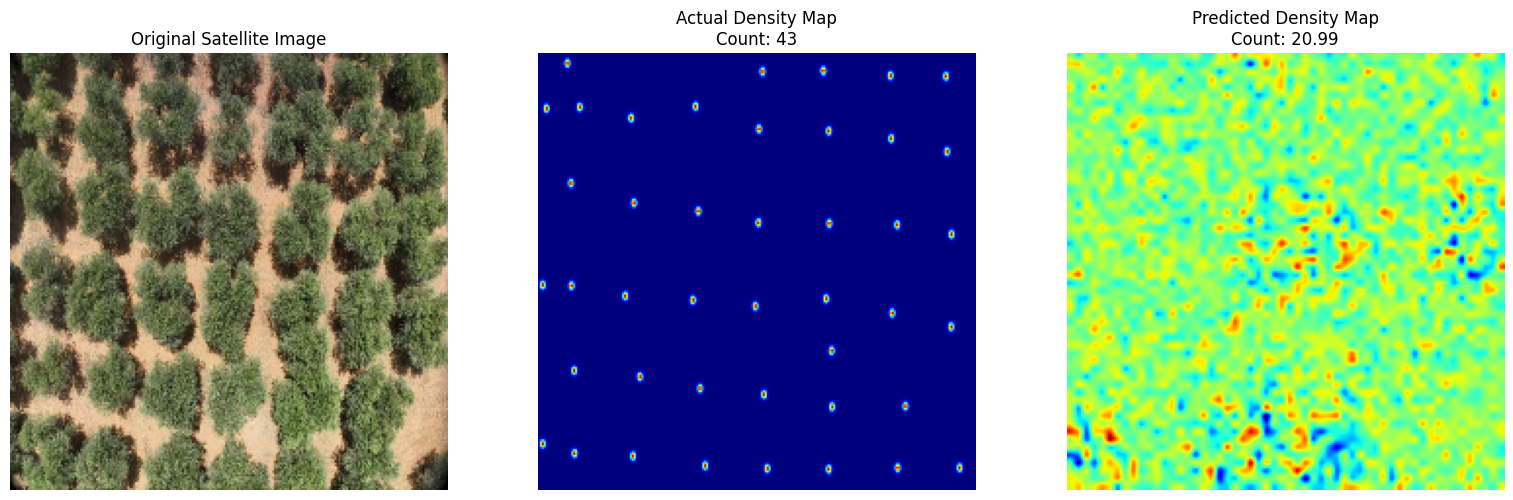

Actual Tree Count: 43
Predicted Tree Count: 20.99
Absolute Error: 22.01


In [ ]:

# CELL 30: VISUALIZE IMPROVED MODEL PREDICTION

import matplotlib.pyplot as plt
import numpy as np
import torch

model.eval()

images, densities = next(iter(test_loader))

images = images.to(device)
densities = densities.to(device)

with torch.no_grad():
    predictions = model(images)

# Select first image
image = images[0].cpu().numpy()
actual_density = densities[0, 0].cpu().numpy()
predicted_density = predictions[0, 0].cpu().numpy()

# Calculate counts using raw sums
actual_count = actual_density.sum()
predicted_count = predicted_density.sum()

# Reverse ImageNet normalization
mean = np.array([0.485, 0.456, 0.406]).reshape(3, 1, 1)
std = np.array([0.229, 0.224, 0.225]).reshape(3, 1, 1)

image = image * std + mean
image = np.clip(image, 0, 1)
image = np.transpose(image, (1, 2, 0))

# Display visualization
plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original Satellite Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(actual_density, cmap="jet")
plt.title(f"Actual Density Map\nCount: {actual_count:.0f}")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(predicted_density, cmap="jet")
plt.title(f"Predicted Density Map\nCount: {predicted_count:.2f}")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Actual Tree Count:", round(float(actual_count)))
print("Predicted Tree Count:", round(float(predicted_count), 2))
print(
    "Absolute Error:",
    round(abs(float(actual_count - predicted_count)), 2)
)


In [ ]:

# CELL 31: SAVE FINAL MODEL AND RESULTS

final_model_path = os.path.join(
    save_dir,
    "final_olive_tree_swin_unet.pth"
)

torch.save(model.state_dict(), final_model_path)

results = {
    "Model": "Swin Transformer U-Net with Count-Aware Fine-Tuning",
    "Training Images": len(train_dataset),
    "Validation Images": len(val_dataset),
    "Testing Images": len(test_dataset),
    "Training Epochs": 10,
    "Fine-tuning Epochs": 5,
    "Best Validation Count MAE": best_count_mae,
    "Test Loss": test_loss,
    "Test Count MAE": test_mae
}

print("FINAL PROJECT RESULTS")
print("------------------------------")

for key, value in results.items():
    print(f"{key}: {value}")

print("\nFinal model saved successfully!")
print(final_model_path)


FINAL PROJECT RESULTS
------------------------------
Model: Swin Transformer U-Net with Count-Aware Fine-Tuning
Training Images: 1124
Validation Images: 141
Testing Images: 140
Training Epochs: 10
Fine-tuning Epochs: 5
Best Validation Count MAE: 17.150269339270626
Test Loss: 0.00011663376873392346
Test Count MAE: 16.080202211652484

Final model saved successfully!
/content/drive/MyDrive/Olive_CNN_Project/Olive_Project/OliveSatelital_v1.0/trained_models/final_olive_tree_swin_unet.pth


In [ ]:

# LOAD FINAL TRAINED MODEL

final_model_path = os.path.join(
    save_dir,
    "final_olive_tree_swin_unet.pth"
)

model.load_state_dict(
    torch.load(final_model_path, map_location=device)
)

model.to(device)
model.eval()

print("Final Olive Tree Model Loaded Successfully!")


Final Olive Tree Model Loaded Successfully!


In [ ]:

# UPLOAD SATELLITE IMAGE

from google.colab import files

uploaded = files.upload()

image_name = next(iter(uploaded))

print("Uploaded Image:", image_name)


Saving Screenshot 2026-11-20 174811.png to Screenshot 2026-11-20 174811.png
Uploaded Image: Screenshot 2026-11-20 174811.png


--------------------------------
OLIVE TREE COUNT PREDICTION
--------------------------------
Predicted Tree Count: -2
--------------------------------


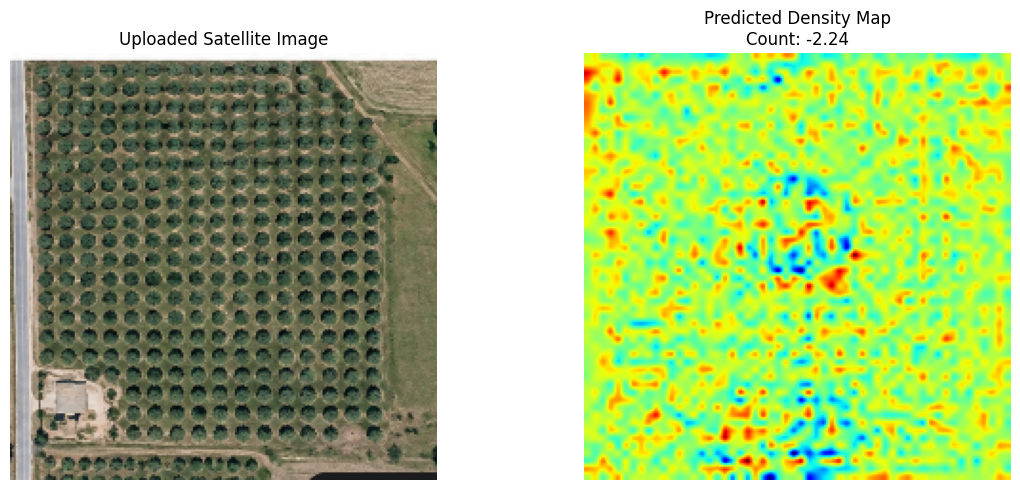

In [ ]:

# OLIVE TREE COUNT PREDICTION

import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt

# Read uploaded image
original_image = cv2.imread(image_name)

if original_image is None:
    raise ValueError("Unable to read uploaded image!")

# Convert BGR to RGB
original_image = cv2.cvtColor(
    original_image,
    cv2.COLOR_BGR2RGB
)

# Resize image to model input size
resized_image = cv2.resize(
    original_image,
    (224, 224)
)

# Normalize image using ImageNet values
image = resized_image.astype(np.float32) / 255.0

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

image = (image - mean) / std

# Convert to PyTorch tensor
image_tensor = torch.from_numpy(
    image.transpose(2, 0, 1)
).float().unsqueeze(0).to(device)

# Predict density map
model.eval()

with torch.no_grad():
    predicted_density = model(image_tensor)

# Calculate predicted tree count
predicted_count = predicted_density.sum().item()

# Get density map for visualization
density_map = predicted_density[0, 0].cpu().numpy()

print("--------------------------------")
print("OLIVE TREE COUNT PREDICTION")
print("--------------------------------")
print("Predicted Tree Count:", round(predicted_count))
print("--------------------------------")

# Display results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(resized_image)
plt.title("Uploaded Satellite Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(density_map, cmap="jet")
plt.title(f"Predicted Density Map\nCount: {predicted_count:.2f}")
plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
print("Raw predicted count:", predicted_density.sum().item())
print("Minimum density:", predicted_density.min().item())
print("Maximum density:", predicted_density.max().item())
print("Actual image size:", original_image.shape)

Raw predicted count: -2.2390382289886475
Minimum density: -0.07410400360822678
Maximum density: 0.05775369703769684
Actual image size: (636, 567, 3)


In [ ]:
# Test using an original test dataset image

model.eval()

image, actual_density = test_dataset[0]

image = image.unsqueeze(0).to(device)

with torch.no_grad():
    predicted_density = model(image)

actual_count = actual_density.sum().item()
predicted_count = predicted_density.sum().item()

print("Actual tree count:", round(actual_count, 2))
print("Predicted tree count:", round(predicted_count, 2))
print("Absolute error:", round(abs(actual_count - predicted_count), 2))

Actual tree count: 43.0
Predicted tree count: 20.99
Absolute error: 22.01


In [ ]:
model.eval()

all_actual = []
all_predicted = []

with torch.no_grad():
    for images, densities in test_loader:

        images = images.to(device)

        predictions = model(images)

        actual_counts = densities.sum(dim=(1, 2, 3))
        predicted_counts = predictions.sum(dim=(1, 2, 3))

        all_actual.extend(actual_counts.cpu().numpy())
        all_predicted.extend(predicted_counts.cpu().numpy())

all_actual = np.array(all_actual)
all_predicted = np.array(all_predicted)

mae = np.mean(np.abs(all_actual - all_predicted))

print("Total test images:", len(all_actual))
print("Actual average count:", all_actual.mean())
print("Predicted average count:", all_predicted.mean())
print("Test Count MAE:", mae)
print("Images with negative predicted counts:", np.sum(all_predicted < 0))

Total test images: 140
Actual average count: 9.478572
Predicted average count: -4.0471706
Test Count MAE: 16.080204
Images with negative predicted counts: 85


In [ ]:

# STEP 1: Create model with non-negative density output

import torch
import torch.nn as nn
import torch.nn.functional as F
import os

class OliveSwinUNetImproved(nn.Module):

    def __init__(self):
        super().__init__()

        self.encoder = timm.create_model(
            "swin_tiny_patch4_window7_224",
            pretrained=False,
            features_only=True,
            out_indices=(0, 1, 2, 3)
        )

        self.decoder3 = ConvBlock(768 + 384, 384)
        self.decoder2 = ConvBlock(384 + 192, 192)
        self.decoder1 = ConvBlock(192 + 96, 96)

        self.final_conv = nn.Conv2d(96, 1, kernel_size=1)

    def forward(self, x):

        f1, f2, f3, f4 = self.encoder(x)

        f1 = f1.permute(0, 3, 1, 2).contiguous()
        f2 = f2.permute(0, 3, 1, 2).contiguous()
        f3 = f3.permute(0, 3, 1, 2).contiguous()
        f4 = f4.permute(0, 3, 1, 2).contiguous()

        x = F.interpolate(
            f4, size=f3.shape[2:],
            mode="bilinear", align_corners=False
        )
        x = self.decoder3(torch.cat([x, f3], dim=1))

        x = F.interpolate(
            x, size=f2.shape[2:],
            mode="bilinear", align_corners=False
        )
        x = self.decoder2(torch.cat([x, f2], dim=1))

        x = F.interpolate(
            x, size=f1.shape[2:],
            mode="bilinear", align_corners=False
        )
        x = self.decoder1(torch.cat([x, f1], dim=1))

        x = F.interpolate(
            x, size=(224, 224),
            mode="bilinear", align_corners=False
        )

        x = self.final_conv(x)

        # Non-negative density prediction
        return F.relu(x)


# Create improved model
improved_model = OliveSwinUNetImproved().to(device)

# Load existing trained weights
old_model_path = os.path.join(
    save_dir,
    "final_olive_tree_swin_unet.pth"
)

checkpoint = torch.load(
    old_model_path,
    map_location=device
)

improved_model.load_state_dict(checkpoint)

improved_model.eval()

print("Improved model created successfully!")
print("Existing trained weights loaded successfully!")
print("Original model checkpoint remains unchanged.")


Improved model created successfully!
Existing trained weights loaded successfully!
Original model checkpoint remains unchanged.


In [ ]:

# STEP 2: Fine-tune improved model

import copy
import torch
import torch.nn.functional as F
import torch.optim as optim
from tqdm import tqdm
import os

# Optimizer
improved_optimizer = optim.AdamW(
    improved_model.parameters(),
    lr=1e-5,
    weight_decay=1e-4
)

# Save improved model separately
improved_save_path = os.path.join(
    save_dir,
    "best_olive_swin_unet_relu.pth"
)

best_val_mae = float("inf")
best_model_weights = None

num_epochs = 5

for epoch in range(num_epochs):

    # -------------------------
    # Training
    # -------------------------
    improved_model.train()

    total_train_loss = 0

    for images, densities in tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{num_epochs} Training"
    ):

        images = images.to(device)
        densities = densities.to(device)

        improved_optimizer.zero_grad()

        predictions = improved_model(images)

        density_loss = F.mse_loss(
            predictions,
            densities
        )

        predicted_counts = predictions.sum(dim=(1, 2, 3))
        actual_counts = densities.sum(dim=(1, 2, 3))

        count_loss = F.l1_loss(
            predicted_counts,
            actual_counts
        ) / (224 * 224)

        loss = density_loss + count_loss

        loss.backward()

        improved_optimizer.step()

        total_train_loss += loss.item()

    avg_train_loss = total_train_loss / len(train_loader)

    # -------------------------
    # Validation
    # -------------------------
    improved_model.eval()

    val_errors = []
    total_val_loss = 0

    with torch.no_grad():

        for images, densities in val_loader:

            images = images.to(device)
            densities = densities.to(device)

            predictions = improved_model(images)

            density_loss = F.mse_loss(
                predictions,
                densities
            )

            predicted_counts = predictions.sum(dim=(1, 2, 3))
            actual_counts = densities.sum(dim=(1, 2, 3))

            count_loss = F.l1_loss(
                predicted_counts,
                actual_counts
            ) / (224 * 224)

            loss = density_loss + count_loss

            total_val_loss += loss.item()

            errors = torch.abs(
                predicted_counts - actual_counts
            )

            val_errors.extend(errors.cpu().numpy())

    avg_val_loss = total_val_loss / len(val_loader)

    val_mae = sum(val_errors) / len(val_errors)

    print(f"\nEpoch [{epoch+1}/{num_epochs}]")
    print(f"Training Loss: {avg_train_loss:.6f}")
    print(f"Validation Loss: {avg_val_loss:.6f}")
    print(f"Validation Count MAE: {val_mae:.4f}")

    # Save best model
    if val_mae < best_val_mae:

        best_val_mae = val_mae

        best_model_weights = copy.deepcopy(
            improved_model.state_dict()
        )

        torch.save(
            best_model_weights,
            improved_save_path
        )

        print("Best improved model saved!")

print("\nFine-tuning completed!")
print("Best Validation Count MAE:", best_val_mae)
print("Saved model:", improved_save_path)


Epoch 1/5 Training: 100%|██████████| 281/281 [00:48<00:00,  5.79it/s]



Epoch [1/5]
Training Loss: 0.000154
Validation Loss: 0.000068
Validation Count MAE: 2.7070
Best improved model saved!


Epoch 2/5 Training: 100%|██████████| 281/281 [00:49<00:00,  5.72it/s]



Epoch [2/5]
Training Loss: 0.000078
Validation Loss: 0.000067
Validation Count MAE: 2.6815
Best improved model saved!


Epoch 3/5 Training: 100%|██████████| 281/281 [00:53<00:00,  5.23it/s]



Epoch [3/5]
Training Loss: 0.000074
Validation Loss: 0.000049
Validation Count MAE: 1.6779
Best improved model saved!


Epoch 4/5 Training: 100%|██████████| 281/281 [00:53<00:00,  5.29it/s]



Epoch [4/5]
Training Loss: 0.000060
Validation Loss: 0.000114
Validation Count MAE: 5.1026


Epoch 5/5 Training: 100%|██████████| 281/281 [00:48<00:00,  5.84it/s]



Epoch [5/5]
Training Loss: 0.000066
Validation Loss: 0.000064
Validation Count MAE: 2.4046

Fine-tuning completed!
Best Validation Count MAE: 1.6779063
Saved model: /content/drive/MyDrive/Olive_CNN_Project/Olive_Project/OliveSatelital_v1.0/trained_models/best_olive_swin_unet_relu.pth


In [ ]:

# STEP 3: Evaluate improved model on test dataset

# Load the best fine-tuned checkpoint
improved_model.load_state_dict(
    torch.load(improved_save_path, map_location=device)
)

improved_model.eval()

all_actual = []
all_predicted = []

with torch.no_grad():

    for images, densities in tqdm(test_loader):

        images = images.to(device)
        densities = densities.to(device)

        predictions = improved_model(images)

        actual_counts = densities.sum(dim=(1, 2, 3))
        predicted_counts = predictions.sum(dim=(1, 2, 3))

        all_actual.extend(actual_counts.cpu().numpy())
        all_predicted.extend(predicted_counts.cpu().numpy())

# Convert to NumPy arrays
all_actual = np.array(all_actual)
all_predicted = np.array(all_predicted)

# Calculate evaluation metrics
test_mae = np.mean(np.abs(all_actual - all_predicted))
test_mse = np.mean((all_actual - all_predicted) ** 2)
test_rmse = np.sqrt(test_mse)

print("\n========== IMPROVED MODEL TEST RESULTS ==========")

print("Total Test Images:", len(all_actual))
print("Actual Average Count:", all_actual.mean())
print("Predicted Average Count:", all_predicted.mean())

print("Test Count MAE:", test_mae)
print("Test Count RMSE:", test_rmse)

print("Negative Predictions:", np.sum(all_predicted < 0))

print("\nOriginal Model Test MAE: 16.0802")
print("Improved Model Test MAE:", round(test_mae, 4))

improvement = (
    (16.0802 - test_mae) / 16.0802
) * 100

print("MAE Improvement (%):", round(improvement, 2))

print("\n==============================================")


100%|██████████| 35/35 [00:06<00:00,  5.50it/s]


========== IMPROVED MODEL TEST RESULTS ==========
Total Test Images: 140
Actual Average Count: 9.478572
Predicted Average Count: 9.137511
Test Count MAE: 1.5513251
Test Count RMSE: 2.1098905
Negative Predictions: 0

Original Model Test MAE: 16.0802
Improved Model Test MAE: 1.5513
MAE Improvement (%): 90.35



In [ ]:

# STEP 4: Save improved final model

final_improved_path = os.path.join(
    save_dir,
    "final_olive_tree_swin_unet_improved.pth"
)

torch.save(
    improved_model.state_dict(),
    final_improved_path
)

print("Improved final model saved successfully!")
print(final_improved_path)


NameError: name 'improved_model' is not defined

In [ ]:

# STEP 5: Test improved model on first test image

improved_model.eval()

image, actual_density = test_dataset[0]

image_tensor = image.unsqueeze(0).to(device)

with torch.no_grad():
    predicted_density = improved_model(image_tensor)

actual_count = actual_density.sum().item()
predicted_count = predicted_density.sum().item()

print("Actual Tree Count:", round(actual_count, 2))
print("Improved Predicted Count:", round(predicted_count, 2))
print(
    "Absolute Error:",
    round(abs(actual_count - predicted_count), 2)
)


Actual Tree Count: 43.0
Improved Predicted Count: 38.27
Absolute Error: 4.73


In [ ]:

# Load improved final model

final_improved_path = os.path.join(
    save_dir,
    "final_olive_tree_swin_unet_improved.pth"
)

improved_model.load_state_dict(
    torch.load(final_improved_path, map_location=device)
)

improved_model.to(device)
improved_model.eval()

print("Improved model loaded successfully!")


NameError: name 'save_dir' is not defined

In [ ]:

from google.colab import files

uploaded = files.upload()

image_name = next(iter(uploaded))

print("Uploaded image:", image_name)


Saving Screenshot 2026-11-20 181737.png to Screenshot 2026-11-20 181737 (2).png
Uploaded image: Screenshot 2026-11-20 181737 (2).png


OLIVE TREE COUNT PREDICTION
Image: Screenshot 2026-11-20 181737 (2).png
Predicted Tree Count: 31
Raw Predicted Count: 30.92


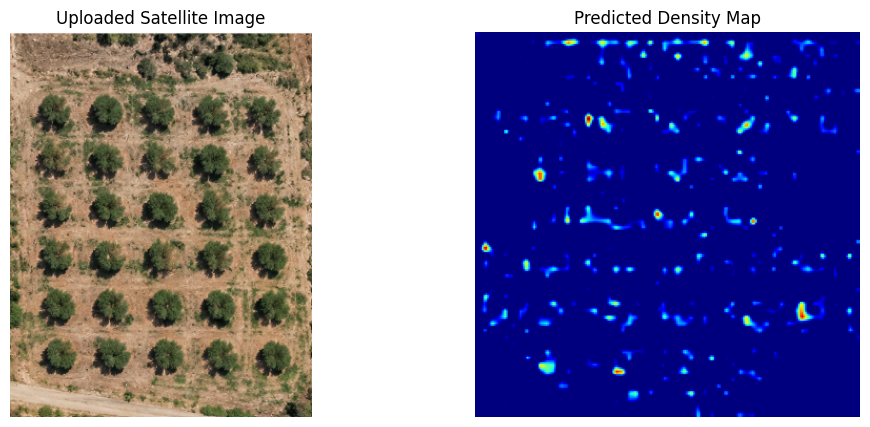

In [ ]:

# Read uploaded image
original_image = cv2.imread(image_name)

if original_image is None:
    raise ValueError("Unable to read uploaded image")

original_image = cv2.cvtColor(
    original_image,
    cv2.COLOR_BGR2RGB
)

# Resize to model input size
resized_image = cv2.resize(
    original_image,
    (224, 224)
)

# Normalize image
image = resized_image.astype(np.float32) / 255.0

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

image = (image - mean) / std

# Convert to tensor
image_tensor = torch.from_numpy(
    image.transpose(2, 0, 1)
).float().unsqueeze(0).to(device)

# Model prediction
improved_model.eval()

with torch.no_grad():
    predicted_density = improved_model(image_tensor)

# Calculate predicted count
predicted_count = predicted_density.sum().item()

density_map = predicted_density[0, 0].cpu().numpy()

print("================================")
print("OLIVE TREE COUNT PREDICTION")
print("================================")
print("Image:", image_name)
print("Predicted Tree Count:", round(predicted_count))
print("Raw Predicted Count:", round(predicted_count, 2))
print("================================")

# Display results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Uploaded Satellite Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(density_map, cmap="jet")
plt.title("Predicted Density Map")
plt.axis("off")

plt.show()


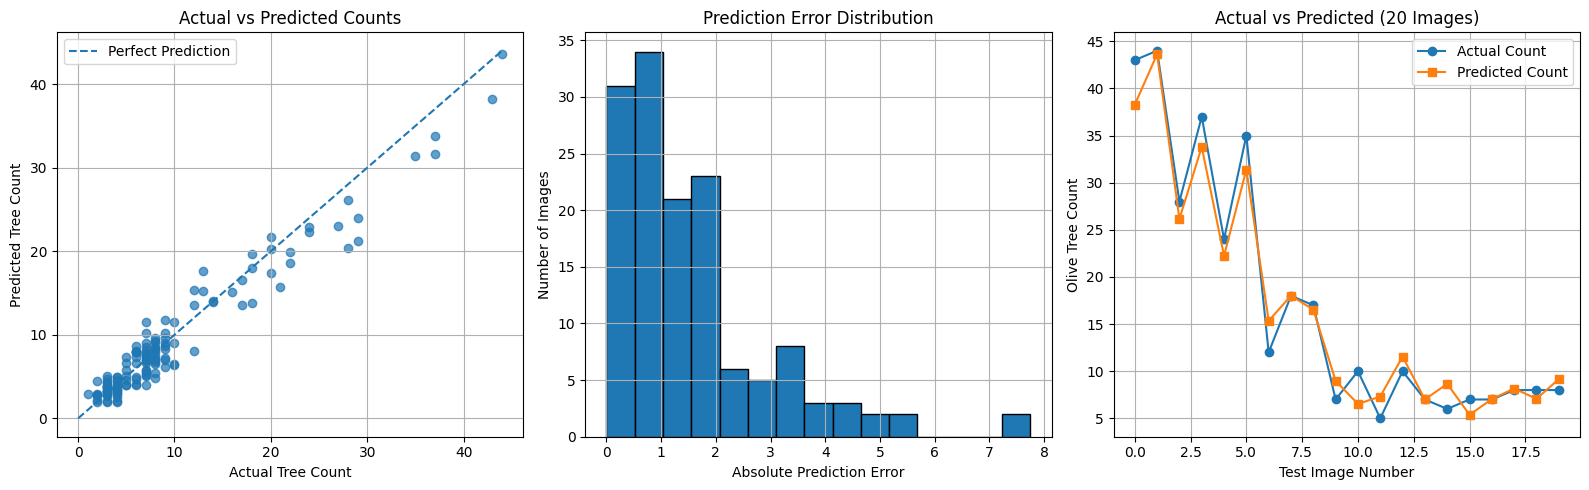

Improved Model Performance
---------------------------
Test MAE: 1.5513
Test RMSE: 2.1099
Total Test Images: 140


In [ ]:

# STEP 12: Visualize Improved Model Results

import matplotlib.pyplot as plt
import numpy as np

# Calculate prediction errors
errors = np.abs(all_actual - all_predicted)

# Create graphs
plt.figure(figsize=(16, 5))

# Graph 1: Actual vs Predicted
plt.subplot(1, 3, 1)

plt.scatter(
    all_actual,
    all_predicted,
    alpha=0.7
)

max_value = max(all_actual.max(), all_predicted.max())

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Tree Count")
plt.ylabel("Predicted Tree Count")
plt.title("Actual vs Predicted Counts")
plt.legend()
plt.grid(True)


# Graph 2: Prediction Error
plt.subplot(1, 3, 2)

plt.hist(
    errors,
    bins=15,
    edgecolor="black"
)

plt.xlabel("Absolute Prediction Error")
plt.ylabel("Number of Images")
plt.title("Prediction Error Distribution")
plt.grid(True)


# Graph 3: First 20 Test Images
plt.subplot(1, 3, 3)

sample = np.arange(20)

plt.plot(
    sample,
    all_actual[:20],
    marker="o",
    label="Actual Count"
)

plt.plot(
    sample,
    all_predicted[:20],
    marker="s",
    label="Predicted Count"
)

plt.xlabel("Test Image Number")
plt.ylabel("Olive Tree Count")
plt.title("Actual vs Predicted (20 Images)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


print("Improved Model Performance")
print("---------------------------")
print("Test MAE:", round(np.mean(errors), 4))
print("Test RMSE:", round(np.sqrt(np.mean((all_actual-all_predicted)**2)), 4))
print("Total Test Images:", len(all_actual))


In [ ]:
import os
import cv2
import timm
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)

Device: cuda


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
base_path = "/content/drive/MyDrive/Olive_CNN_Project/Olive_Project/OliveSatelital_v1.0"

save_dir = os.path.join(base_path, "trained_models")

final_improved_path = os.path.join(
    save_dir,
    "final_olive_tree_swin_unet_improved.pth"
)

print("Model exists:", os.path.exists(final_improved_path))
print("Model path:", final_improved_path)

Model exists: True
Model path: /content/drive/MyDrive/Olive_CNN_Project/Olive_Project/OliveSatelital_v1.0/trained_models/final_olive_tree_swin_unet_improved.pth


In [ ]:
improved_model = OliveSwinUNetImproved().to(device)

improved_model.load_state_dict(
    torch.load(final_improved_path, map_location=device)
)

improved_model.eval()

print("Improved Olive Tree Model Loaded Successfully!")

Improved Olive Tree Model Loaded Successfully!


In [ ]:

import numpy as np
import torch

improved_model.eval()

all_actual = []
all_predicted = []

with torch.no_grad():
    for images, densities in test_loader:

        images = images.to(device)
        densities = densities.to(device)

        predictions = improved_model(images)

        actual_counts = densities.sum(dim=(1, 2, 3))
        predicted_counts = predictions.sum(dim=(1, 2, 3))

        all_actual.extend(actual_counts.cpu().numpy())
        all_predicted.extend(predicted_counts.cpu().numpy())

all_actual = np.array(all_actual)
all_predicted = np.array(all_predicted)

print("Test images:", len(all_actual))
print("Actual counts:", all_actual[:5])
print("Predicted counts:", all_predicted[:5])


Test images: 140
Actual counts: [43.       44.       28.       36.999996 24.      ]
Predicted counts: [38.272472 43.625507 26.144102 33.791702 22.24591 ]


In [ ]:
errors = np.abs(all_actual - all_predicted)

print("MAE:", np.mean(errors))
print("RMSE:", np.sqrt(np.mean((all_actual - all_predicted)**2)))

MAE: 1.5513251
RMSE: 2.1098905
